# Week 6 Assignment: Probabilistic Forecasting & Risk
**DSE6230: Forecasting Methods and Applications**

In this assignment, you will transition from generating single point estimates to producing and evaluating **probabilistic forecasts**. You will learn how to quantify uncertainty and translate statistical ranges into business decisions.

In [2]:
!pip install pandas numpy matplotlib statsforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.8 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoARIMA

In [4]:
# Raw data: swap this for a dataset of your choice (e.g., energy demand or retail sales)
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
raw = pd.read_csv(url, parse_dates=['Month'])
df = pd.DataFrame({
    'unique_id': 'series_1',
    'ds': raw['Month'],
    'y': raw['Passengers'],
})

## Task 1: Generating Prediction Intervals
Using a dataset of your choice (e.g., energy demand or retail sales), fit an **AutoETS** model.

1. Generate forecasts for a 12-month horizon.
2. Ensure you include **80% and 95% prediction intervals**.
3. Plot the results using `StatsForecast.plot`.

,unique_id,ds,AutoETS,AutoETS-lo-95,AutoETS-lo-80,AutoETS-hi-80,AutoETS-hi-95,width_80,width_95
0,series_1,1961-01-01,442.399994,399.100006,414.100006,470.600006,485.600006,56.599998,86.500000
1,series_1,1961-02-01,428.299988,382.399994,398.299988,458.299988,474.200012,60.000000,91.800003
2,series_1,1961-03-01,493.000000,443.799988,460.799988,525.099976,542.099976,64.300003,98.300003
3,series_1,1961-04-01,477.399994,425.299988,443.299988,511.399994,529.400024,68.000000,104.099998
4,series_1,1961-05-01,477.600006,422.799988,441.799988,513.400024,532.400024,71.599998,109.500000
5,series_1,1961-06-01,535.900024,477.799988,497.899994,573.799988,593.900024,75.900002,116.099998
6,series_1,1961-07-01,600.799988,539.000000,560.400024,641.299988,662.700012,80.900002,123.800003
7,series_1,1961-08-01,594.799988,529.299988,552.000000,637.599976,660.200012,85.599998,130.899994
8,series_1,1961-09-01,513.700012,445.700012,469.299988,558.099976,581.700012,88.900002,135.899994
9,series_1,1961-10-01,448.200012,378.399994,402.600006,493.899994,518.099976,91.300003,139.699997


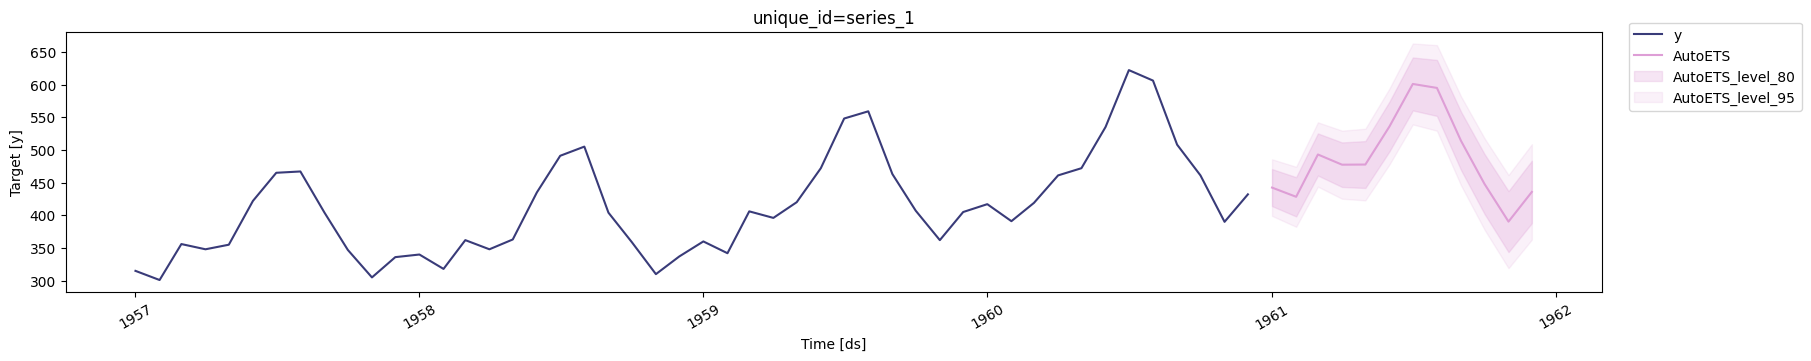

In [13]:
from statsforecast import models
# Your Code Here
horizon = 12

sf = StatsForecast(models=[AutoETS(season_length=12)], freq = "MS") # Monthly data
sf.fit(df)
forecasts = sf.predict(h=horizon, level=[80,95])  # adds lo/hi columns for each level
forecasts.head()




## Task 2: Evaluating the Distribution
Forecasts are only useful if their uncertainty is well-calibrated.

1. Perform a **backtest** (rolling-origin cross-validation) on your data.
2. Calculate the **Coverage** of your intervals: How often did the actual value fall within the 80% interval?
3. If the actual coverage is only 60%, what does that tell you about your model?

In [14]:
# Your Code Here
# Task 2: rolling-origin backtest + interval coverage
# 4 origins, one per year (end of 1956, 1957, 1958, 1959); each forecasts the next 12 months
sf_cv = StatsForecast(models=[AutoETS(season_length=12), AutoARIMA(season_length=12)], freq="MS")
cv = sf_cv.cross_validation(df=df, h=horizon, n_windows=4, step_size=12, level=[80, 95])

rows = []
for m in ["AutoETS", "AutoARIMA"]:
    for lv in [80, 95]:
        lo, hi = cv[f"{m}-lo-{lv}"], cv[f"{m}-hi-{lv}"]
        rows.append({
            "model": m,
            "nominal": f"{lv}%",
            "actual coverage": ((cv["y"] >= lo) & (cv["y"] <= hi)).mean(),
            "missed above": (cv["y"] > hi).mean(),     # actual higher than the upper bound
            "missed below": (cv["y"] < lo).mean(),     # actual lower than the lower bound
            "avg width": (hi - lo).mean(),
            "bias (actual - forecast)": (cv["y"] - cv[m]).mean(),
        })
coverage = pd.DataFrame(rows)
print(f"{len(cv)} backtest forecasts from {cv['cutoff'].nunique()} origins")
coverage.style.format({"actual coverage": "{:.0%}", "missed above": "{:.0%}", "missed below": "{:.0%}", "avg width": "{:.1f}", "bias (actual - forecast)": "{:+.1f}"})

48 backtest forecasts from 4 origins


,model,nominal,actual coverage,missed above,missed below,avg width,bias (actual - forecast)
0,AutoETS,80%,50%,44%,6%,62.1,+26.6
1,AutoETS,95%,73%,27%,0%,95.0,+26.6
2,AutoARIMA,80%,62%,27%,10%,52.3,+5.2
3,AutoARIMA,95%,83%,15%,2%,80.0,+5.2


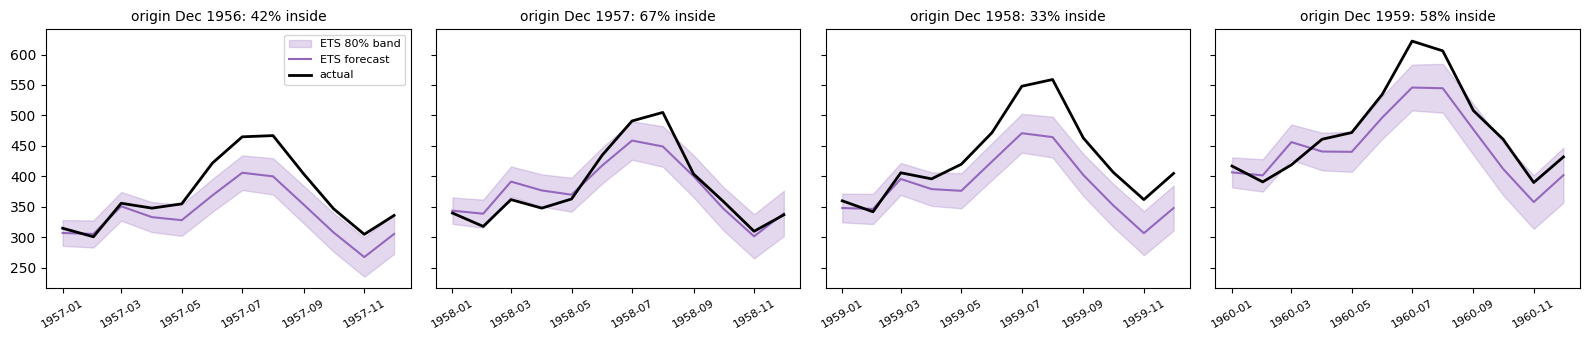

In [15]:
# Each backtest window: actuals vs the AutoETS 80% band
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (cutoff, g) in zip(axes, cv.groupby("cutoff")):
    ax.fill_between(g["ds"], g["AutoETS-lo-80"], g["AutoETS-hi-80"], color="tab:purple", alpha=0.25, label="ETS 80% band")
    ax.plot(g["ds"], g["AutoETS"], color="tab:purple", label="ETS forecast")
    ax.plot(g["ds"], g["y"], color="black", lw=2, label="actual")
    inside = ((g["y"] >= g["AutoETS-lo-80"]) & (g["y"] <= g["AutoETS-hi-80"])).mean()
    ax.set_title(f"origin {cutoff:%b %Y}: {inside:.0%} inside", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Task 2: Results**

I backtested with 4 rolling origins (Dec 1956–Dec 1959), each forecasting the next 12 months, for 48 forecasts in total.

**Coverage:** the AutoETS 80% interval contained the actual value only **50%** of the time, and the 95% interval only 73%. AutoARIMA did better (62% and 83%) but still fell short of the nominal levels.

**Why:** the misses are lopsided. 44% of actuals landed *above* the ETS 80% band and only 6% below. The model AutoETS selected, ETS(M,N,M), has no trend term, so on a growing series it under-forecasts by about 27 passengers on average, and the band is centered too low.

**What 60% coverage would mean:** the intervals are too narrow, so the model is **overconfident**. It claims 80% certainty but is right only 60% of the time. Common causes:
- **A misspecified model**, like a missing trend here: the center of the forecast is biased, so even correct-width bands miss.
- **Residuals that break the model's assumptions** (autocorrelated, skewed or changing variance), so the textbook interval formula understates the spread.
- **Ignored uncertainty:** the intervals assume the fitted parameters and the chosen model are exactly right.
- **Structural change** in the future that history doesn't show.

**What to do:** fix the model first (for example, force a damped or additive trend, or use ARIMA), then calibrate the intervals empirically, e.g. with conformal prediction (`ConformalIntervals` in statsforecast), which builds intervals from actual backtest errors. Until then, any decision based on these bands, like the safety stock in Task 3, would understate risk.

## Task 3: Prescriptive Analysis (What-If)
Imagine you are an inventory manager. An under-forecast (stockout) costs \$10 per unit in lost revenue, while an over-forecast (excess inventory) costs \$2 per unit in holding costs.

1. Use the **90th percentile** of your forecast distribution as your "Order Level."
2. Calculate the "Safety Stock" (The difference between your 90th percentile forecast and the mean forecast).
3. **Synthesis**: Write a 1-paragraph recommendation to an executive explaining why ordering based on the *mean* forecast might be financially riskier than ordering based on the *90th percentile*.

In [16]:
# Your Code Here
# Task 3: order level = 90th percentile, safety stock = P90 - mean
# For a symmetric 80% interval, the upper bound IS the 90th percentile (10% of outcomes lie above it).
plan = forecasts[["ds", "AutoETS", "AutoETS-hi-80"]].rename(columns={"AutoETS": "mean_forecast", "AutoETS-hi-80": "order_level_p90"})
plan["safety_stock"] = plan["order_level_p90"] - plan["mean_forecast"]
display(plan.round(1))
print(f"Total 1961 safety stock: {plan['safety_stock'].sum():,.0f} units "
      f"({plan['safety_stock'].sum() / plan['mean_forecast'].sum():.1%} above the mean forecast)")

# What-if: replay both ordering rules on the Task 2 backtest (48 months with known actuals)
COST_UNDER, COST_OVER = 10, 2          # $ per unit short (lost revenue) / per unit left over (holding)

def cost(order, actual):
    return COST_UNDER * np.maximum(actual - order, 0) + COST_OVER * np.maximum(order - actual, 0)

whatif = pd.DataFrame({
    "order rule": ["Mean forecast", "90th percentile"],
    "stockout months": [(cv["y"] > cv["AutoETS"]).mean(), (cv["y"] > cv["AutoETS-hi-80"]).mean()],
    "avg cost / month ($)": [cost(cv["AutoETS"], cv["y"]).mean(), cost(cv["AutoETS-hi-80"], cv["y"]).mean()],
})
print(f"\nBest service level for these costs (critical ratio) = {COST_UNDER}/({COST_UNDER}+{COST_OVER}) = {COST_UNDER/(COST_UNDER+COST_OVER):.0%}")
whatif.style.format({"stockout months": "{:.0%}", "avg cost / month ($)": "${:,.0f}"})

,ds,mean_forecast,order_level_p90,safety_stock
0,1961-01-01,442.399994,470.600006,28.299999
1,1961-02-01,428.299988,458.299988,30.000000
2,1961-03-01,493.000000,525.099976,32.099998
3,1961-04-01,477.399994,511.399994,34.000000
4,1961-05-01,477.600006,513.400024,35.799999
5,1961-06-01,535.900024,573.799988,37.900002
6,1961-07-01,600.799988,641.299988,40.500000
7,1961-08-01,594.799988,637.599976,42.799999
8,1961-09-01,513.700012,558.099976,44.400002
9,1961-10-01,448.200012,493.899994,45.700001


Total 1961 safety stock: 466 units (8.0% above the mean forecast)

Best service level for these costs (critical ratio) = 10/(10+2) = 83%


,order rule,stockout months,avg cost / month ($)
0,Mean forecast,79%,$303
1,90th percentile,44%,$119


**Recommendation:**

We should order at the 90th percentile of the forecast, not the mean. A stockout costs 10 dollars per unit while excess stock costs only 2 dollars, so running short is 5 times worse than running long, and the mean forecast runs short about half the time. In a 4-year backtest, ordering at the mean cost about 303 dollars per month, while ordering at the 90th percentile cost about 119 dollars, 61% less. For 1961 this means holding 466 units of safety stock, about 8% above the mean forecast. One caveat: the model's intervals proved too narrow in backtesting, so we should fix its missing trend before relying on this policy.

## Submission
Submit your completed notebook showing all plots and your prescriptive synthesis.

## Grading Rubric
- **Correctness (40%)**: Does the code run and produce the expected output?
- **Code Quality (30%)**: Is the code clean, commented, and efficient?
- **Analysis (30%)**: Are the interpretations and explanations clear and accurate?